# 05 Explainability (Day 10)

Steps in this notebook: SHAP explanation (this part), then calibration and threshold, error analysis, subgroup audit, and the one-time test evaluation.

All analysis uses the **validation split**. The test split is not touched in this part.

Setup: run from the repo root so `src` and `data/` resolve.

In [1]:
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print(os.getcwd())

d:\ml-engineer-internship


Imports.

In [2]:
import joblib  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import shap  # noqa: E402

from src.pipeline import (  # noqa: E402
    CATEGORICAL_FEATURES,
    NUMERIC_FEATURES,
    load_splits,
    split_xy,
)

os.makedirs("reports/figures", exist_ok=True)

d:\ml-engineer-internship\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Load the saved model and the validation split (the test split is ignored here).

In [3]:
model = joblib.load("models/best_model.joblib")
_train, val, _test = load_splits()
val_x, val_y = split_xy(val)
y_val = val_y.to_numpy()
proba = model.predict_proba(val_x)[:, 1]
print(val_x.shape, "positives:", int(y_val.sum()))

(3750, 9) positives: 147


Split the pipeline into its preprocessing and XGBoost parts, so SHAP sees the model's real input columns with readable names.

In [4]:
prep = model.named_steps["prep"]
clf = model.named_steps["clf"]
x_val_t = np.asarray(prep.transform(val_x), dtype=float)
names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
print(x_val_t.shape, names[:6])

(3750, 28) ['session_duration_sec', 'payload_size_kb', 'latency_ms', 'retry_count', 'interaction_type_agent_orchestration', 'interaction_type_api_query']


Compute exact TreeSHAP values (log-odds units) for every validation row.

In [5]:
explainer = shap.TreeExplainer(clf)
sv = explainer.shap_values(x_val_t)
print(sv.shape)

(3750, 28)


Beeswarm summary plot: each dot is one row, colour is the feature value, position is its push on the prediction. Saved to `reports/figures/shap_summary.png`.

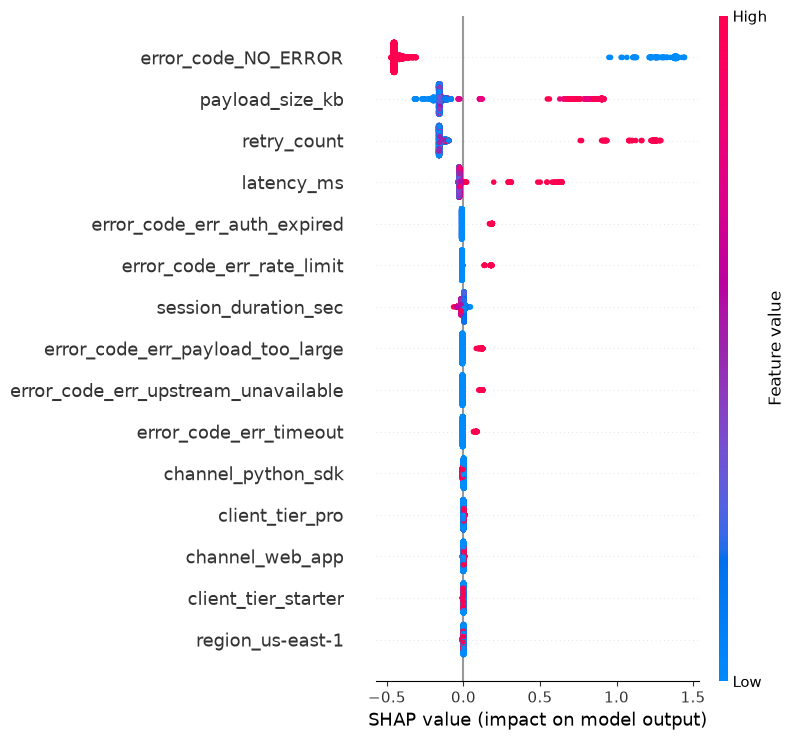

In [6]:
shap.summary_plot(sv, x_val_t, feature_names=names, max_display=15, show=False)
plt.savefig("reports/figures/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

Mean absolute SHAP bar chart for the top 15 model inputs. Saved to `reports/figures/shap_importance.png`.

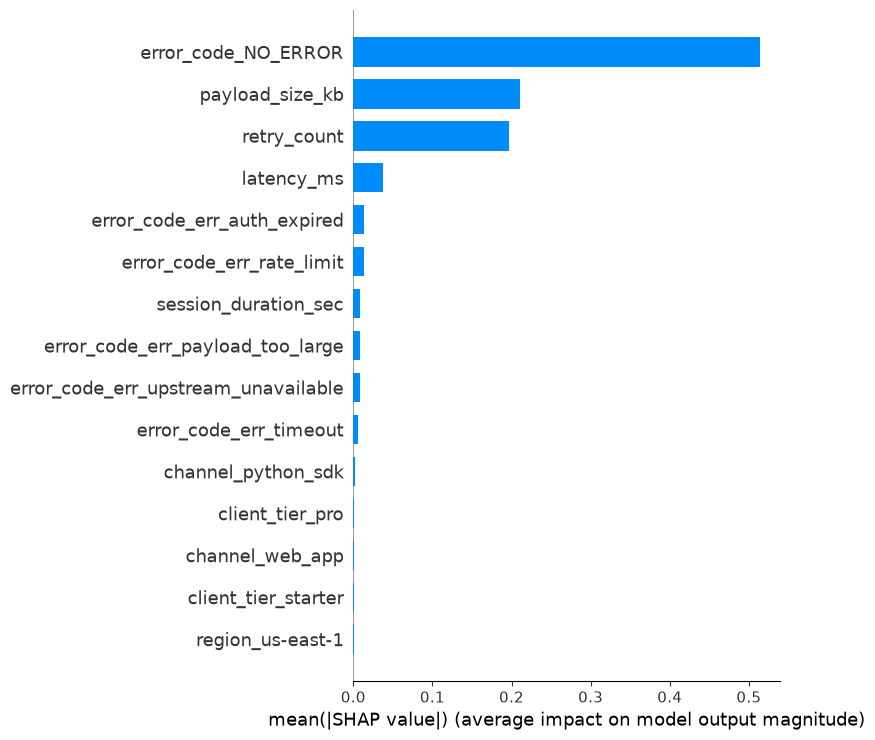

In [7]:
shap.summary_plot(
    sv, x_val_t, feature_names=names, plot_type="bar", max_display=15, show=False
)
plt.savefig("reports/figures/shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

Importance per original column: adds up each column's one-hot pieces per row first, so the totals are exact (this answers Gate 2 probe 2: which feature is strongest).

In [8]:
def original_column(name):
    for col in NUMERIC_FEATURES + CATEGORICAL_FEATURES:
        if name == col or name.startswith(col + "_"):
            return col
    return name


groups = {}
for i, n in enumerate(names):
    groups.setdefault(original_column(n), []).append(i)
by_column = (
    pd.Series({c: np.abs(sv[:, idx].sum(axis=1)).mean() for c, idx in groups.items()})
    .sort_values(ascending=False)
    .round(4)
)
by_column.to_csv("reports/shap_by_column.csv", header=["mean_abs_shap"])
by_column

error_code              0.5581
payload_size_kb         0.2113
retry_count             0.1964
latency_ms              0.0379
session_duration_sec    0.0085
channel                 0.0033
client_tier             0.0019
region                  0.0010
interaction_type        0.0007
dtype: float32

Direction check for `error_code`: for each code, how many rows have it and whether it pushes the anomaly score up (positive) or down (negative).

In [9]:
rows = []
for i, n in enumerate(names):
    if n.startswith("error_code_"):
        active = x_val_t[:, i] == 1
        if active.sum() > 0:
            rows.append(
                {
                    "category": n,
                    "n_rows": int(active.sum()),
                    "mean_shap_when_active": round(float(sv[active, i].mean()), 4),
                }
            )
pd.DataFrame(rows).sort_values("mean_shap_when_active", ascending=False)

,category,n_rows,mean_shap_when_active
1,error_code_err_auth_expired,63,0.1859
3,error_code_err_rate_limit,74,0.1771
5,error_code_err_upstream_unavailable,53,0.1212
2,error_code_err_payload_too_large,62,0.1182
4,error_code_err_timeout,47,0.0817
0,error_code_NO_ERROR,3451,-0.4421


Waterfall plots for 3 single predictions: the most confident true positive, the most confident false positive, and a missed anomaly (false negative). Saved to `reports/figures/`.

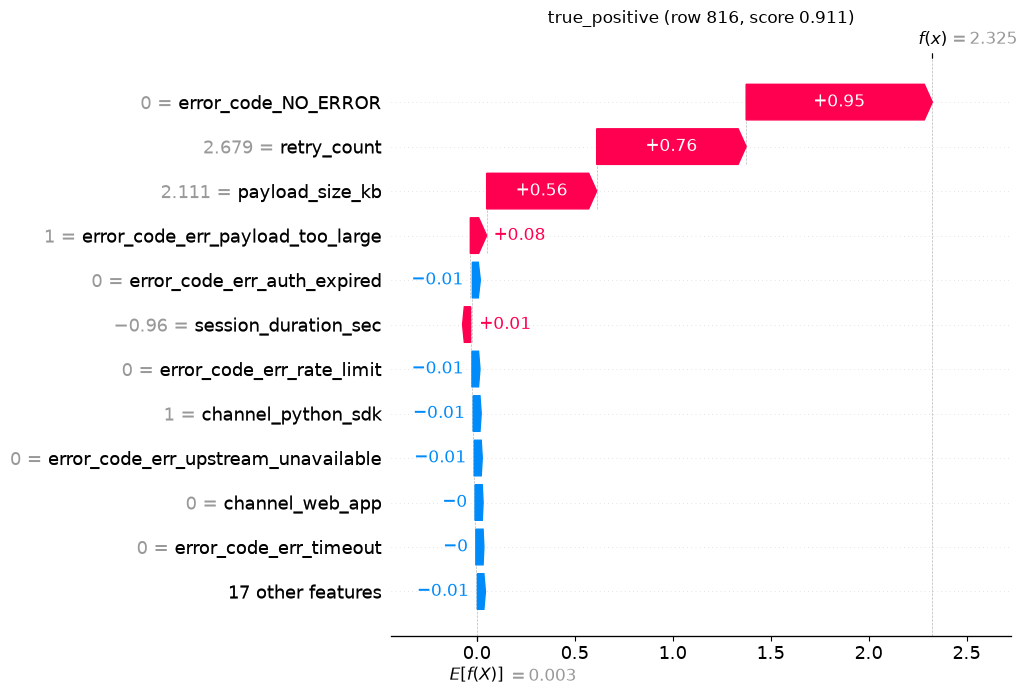

true_positive row 816 score 0.911


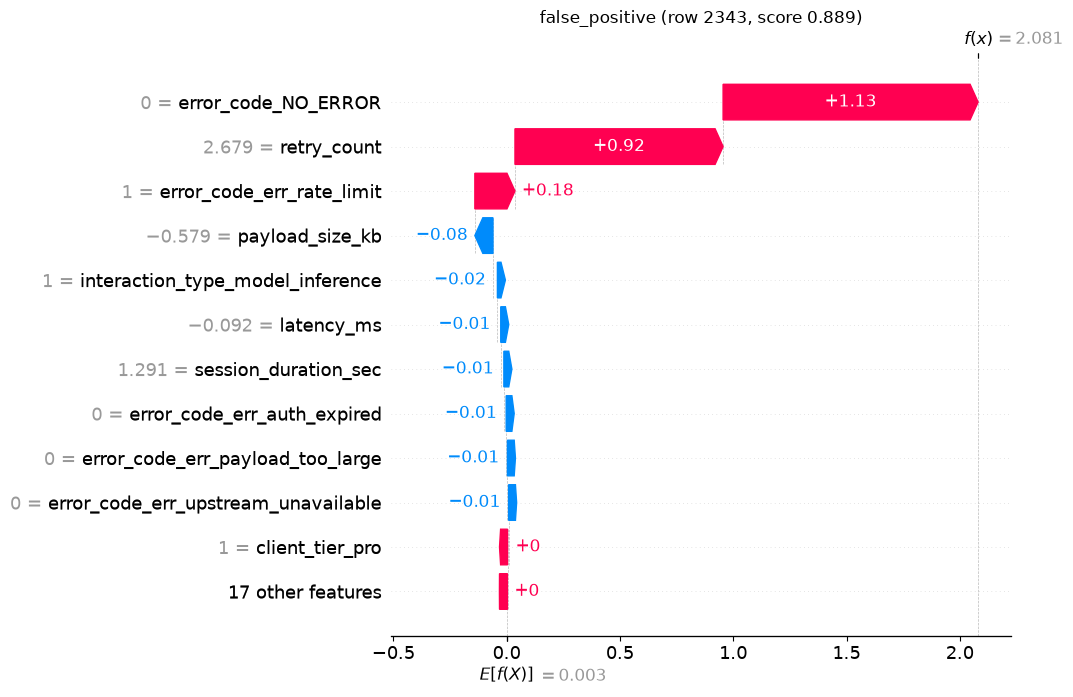

false_positive row 2343 score 0.889


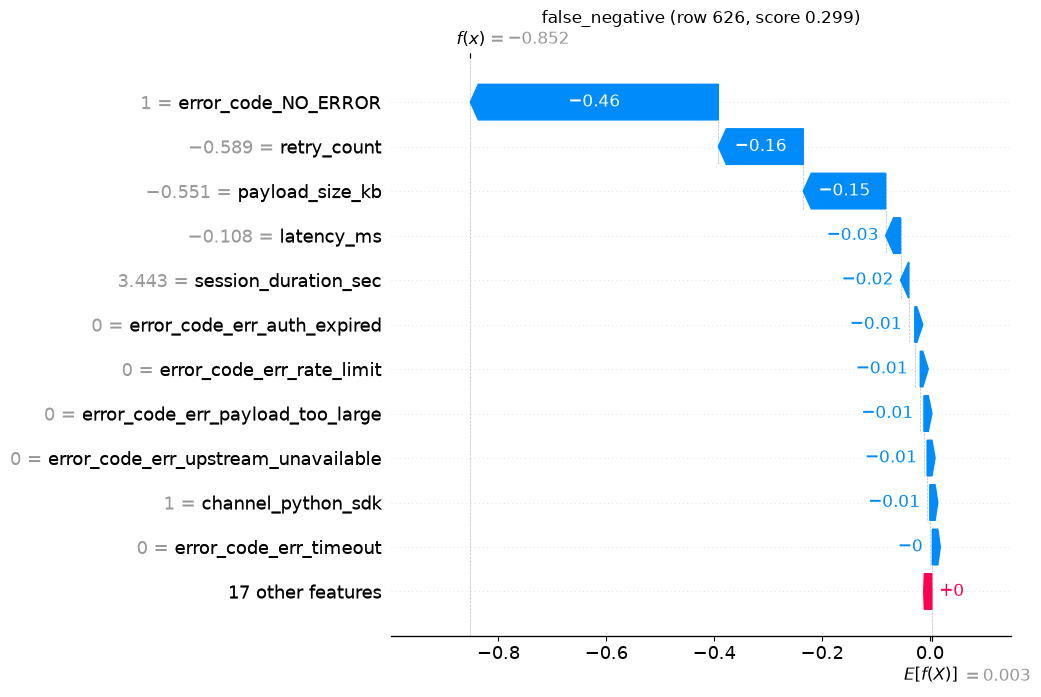

false_negative row 626 score 0.299


In [10]:
pos = np.where(y_val == 1)[0]
neg = np.where(y_val == 0)[0]
picks = {
    "true_positive": pos[np.argmax(proba[pos])],
    "false_positive": neg[np.argmax(proba[neg])],
    "false_negative": pos[np.argmin(proba[pos])],
}
base_value = float(np.ravel(explainer.expected_value)[0])
for label, i in picks.items():
    exp = shap.Explanation(
        values=sv[i],
        base_values=base_value,
        data=x_val_t[i],
        feature_names=names,
    )
    shap.plots.waterfall(exp, max_display=12, show=False)
    plt.title(f"{label} (row {i}, score {proba[i]:.3f})")
    plt.savefig(f"reports/figures/shap_waterfall_{label}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(label, "row", int(i), "score", round(float(proba[i]), 4))

In [11]:
# Probe 2 check: does the model still work without error_code? Same params, same folds.
from sklearn.base import clone  # noqa: E402
from sklearn.model_selection import StratifiedKFold, cross_validate  # noqa: E402
from xgboost import XGBClassifier  # noqa: E402

from src.pipeline import SEED, build_pipeline  # noqa: E402

x_tr, y_tr = split_xy(_train)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"pr": "average_precision", "roc": "roc_auc"}

with_ec = cross_validate(clone(model), x_tr, y_tr, cv=folds, scoring=scoring)
no_ec_pipe = build_pipeline(
    XGBClassifier(**clf.get_params()),
    cat_cols=[c for c in CATEGORICAL_FEATURES if c != "error_code"],
)
no_ec = cross_validate(no_ec_pipe, x_tr, y_tr, cv=folds, scoring=scoring)

for label, res in [("with error_code", with_ec), ("without error_code", no_ec)]:
    print(
        label,
        "PR-AUC", round(res["test_pr"].mean(), 4), "+-", round(res["test_pr"].std(), 4),
        "| ROC-AUC", round(res["test_roc"].mean(), 4),
    )

with error_code PR-AUC 0.2715 +- 0.0286 | ROC-AUC 0.8172
without error_code PR-AUC 0.1261 +- 0.0076 | ROC-AUC 0.6658


## SHAP findings

- Strongest feature: error_code (mean |SHAP| 0.558), followed by payload_size_kb (0.211), retry_count (0.196), and latency_ms (0.038).
- Direction: Error codes increase anomaly scores, while NO_ERROR decreases them.
- Waterfall analysis: Examined one true positive, one false positive, and one false negative.
- Model scores are not calibrated probabilities. Calibration and threshold selection are handled in the next step.
- Feature values in waterfall plots are standardized.